# 🕸️ LangGraph 기초부터 차근차근
---
## 🧭 학습 로드맵

| 단계 | # | 주제 | 핵심 키워드 | LLM 필요? |
|:----:|:-:|------|-------------|:---------:|
| 🌱 **기초** | 1 | LangGraph 란? | State · Node · Edge · 슈퍼스텝 | ❌ |
| | 2 | 첫 번째 그래프 | `StateGraph`, `compile`, `invoke` | ❌ |
| | 3 | 노드 여러 개 연결 | 순차 실행, 상태 갱신 규칙 | ❌ |
| | 4 | State 스키마 | `TypedDict` / `dataclass` / `Pydantic`, 입력·출력 스키마 | ❌ |
| | 5 | 리듀서 | `Annotated`, `operator.add`, `add_messages` | ❌ |
| 🌿 **흐름 제어** | 6 | 조건부 엣지 | `add_conditional_edges` | ❌ |
| | 7 | 반복(사이클) | 루프, `recursion_limit` | ❌ |
| | 8 | 병렬 실행 | fan-out / fan-in | ❌ |
| | 9 | `Send` | 개수가 정해지지 않은 병렬(Map-Reduce) | ❌ |
| | 10 | `Command` | 상태 업데이트 + 이동 한 번에 | ❌ |
| | 11 | 런타임 컨텍스트 | `context_schema`, `Runtime` | ❌ |
| 🌳 **LLM 에이전트** | 12 | LLM 노드 · 챗봇 | `MessagesState` | ✅ |
| | 13 | LLM 라우팅 | 구조화된 출력 + 조건부 엣지 | ✅ |
| | 14 | 도구 에이전트 (ReAct) | `ToolNode`, `tools_condition` | ✅ |
| 🌲 **운영 기능** | 15 | 메모리 | 체크포인터, `thread_id` | ✅ |
| | 16 | 스트리밍 | `stream_mode` 5가지 | ✅ |
| | 17 | Human-in-the-loop | `interrupt`, `Command(resume)` | ❌ |
| | 18 | 에러 처리 | `RetryPolicy` | ❌ |
| | 19 | 서브그래프 | 그래프 안의 그래프 | ❌ |
| 🏁 **종합** | 20 | 글쓰기 에이전트 | 루프 + 사람 피드백 + LLM | ✅ |
| | 21 | 정리 | 치트시트 · 연습문제 · 다음 단계 | ❌ |

> **한눈에 보기**
> - LLM 노드(`MessagesState`), LLM 라우터(`with_structured_output` + 조건부 엣지), ReAct 에이전트(`ToolNode` + `tools_condition` 사이클)
> - 체크포인터 + `thread_id` 메모리, `get_state` / `get_state_history`, `stream_mode` 5가지(values·updates·custom·messages·debug)
> - `interrupt()` + `Command(resume=)` 사람 승인 — **재개하면 노드가 처음부터 다시 실행**, 정적 중단점 `interrupt_before`
> - `RetryPolicy` 노드 재시도, 서브그래프, 종합: 사람 피드백을 반영하는 글쓰기 에이전트
> - 정리 문서: [LangGraph에이전트와운영.md](LangGraph에이전트와운영.md) · 노트북 로드맵 12~21장, 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

## 0️⃣ 환경 설정

In [1]:
import sys
from importlib.metadata import version

print("Python           :", sys.version.split()[0])
for pkg in ("langgraph", "langchain", "langchain-core", "langchain-openai"):
    print(f"{pkg:17s}:", version(pkg))

MODEL = "gpt-4o-mini"      # 12장부터 사용할 모델

Python           : 3.12.10
langgraph        : 1.2.16
langchain        : 1.4.6
langchain-core   : 1.6.12
langchain-openai : 1.7.2


In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [3]:
from IPython.display import Image, display

def show_graph(g, xray: bool = False):
    """그래프 구조를 그림으로 보여준다. PNG 실패 시 Mermaid 텍스트를 출력한다."""
    drawable = g.get_graph(xray=xray)
    try:
        display(Image(drawable.draw_mermaid_png()))
    except Exception:
        print(drawable.draw_mermaid())
        print("ℹ️ 위 Mermaid 텍스트를 https://mermaid.live 에 붙여 넣으면 그림으로 볼 수 있어요")

**State · Node · Edge · 리듀서 · 조건부 엣지 · 루프 · 병렬 · Send · Command · Context** — 이 10가지만 이해하면 LangGraph 의 뼈대는 끝입니다.
이제 이 뼈대에 **LLM 을 끼워 넣어** 진짜 에이전트를 만들어 봅니다.

## 🌳 12장. LLM 노드 : 가장 단순한 챗봇 그래프

### 📖 이론

드디어 LLM 을 붙입니다. 놀랍게도 **새로 배울 문법은 없습니다.**
**"LLM 호출은 그냥 노드 함수 안에서 `llm.invoke()` 를 부르는 것"** 입니다. (LangChain 에서 배운 모델 객체를 그대로 사용)

```python
def chatbot(state: MessagesState):
    ai_message = llm.invoke(state["messages"])      # 👈 LangChain 모델 호출
    return {"messages": [ai_message]}               # 👈 응답을 messages 에 추가
```

#### 🧱 `MessagesState` — 대화용 기본 State

대화형 에이전트의 State 는 거의 항상 `messages` 하나로 시작합니다. LangGraph 가 이를 미리 만들어 둔 것이 **`MessagesState`** 입니다.

```python
class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]    # 5장에서 배운 add_messages 리듀서!
```

- 노드가 `{"messages": [새 메시지]}` 를 반환하면 **기존 대화 뒤에 자동으로 이어 붙습니다.** (덮어쓰기 ❌)
- 입력도 `{"messages": [HumanMessage("안녕")]}` 또는 `{"messages": [("user", "안녕")]}` 처럼 간단히 줄 수 있습니다.

```
 START ──▶ 🤖 chatbot ──▶ END
            │  state["messages"] = [Human]
            └▶ llm.invoke(...) → AIMessage → messages = [Human, AI]
```

#### 🔑 API 키 준비
12장부터는 OpenAI API 키가 필요합니다. (아래 셀에서 입력)

In [4]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model=MODEL, temperature=0)       # LangChain 에서 배운 그 모델 객체!
print("✅ LLM 준비 완료:", MODEL)

✅ LLM 준비 완료: gpt-4o-mini


In [5]:
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage, SystemMessage

def chatbot(state: MessagesState) -> dict:
    system = SystemMessage("당신은 친절한 IT 강사입니다. 한국어로 두 문장 이내로 답하세요.")
    ai_message = llm.invoke([system] + state["messages"])       # 시스템 프롬프트는 저장하지 않고 호출 때만 앞에 붙임
    return {"messages": [ai_message]}

builder = StateGraph(MessagesState)
builder.add_node("chatbot", chatbot)

builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)
chat_graph = builder.compile()

In [6]:
result = chat_graph.invoke({"messages": [HumanMessage("LangGraph 가 뭐야?")]})
for m in result["messages"]:
    m.pretty_print()                       # 메시지를 보기 좋게 출력

================================ Human Message =================================

LangGraph 가 뭐야?
================================== Ai Message ==================================

LangGraph는 자연어 처리(NLP)와 그래프 기반 데이터 구조를 결합하여 언어 데이터를 분석하고 이해하는 데 도움을 주는 도구입니다. 이를 통해 텍스트 간의 관계를 시각화하고, 의미를 파악하는 데 유용합니다.


**📝 정리** — 응답이 두 메시지로 쌓인 것은 `add_messages` 덕분. 그런데 gpt-4o-mini가 LangGraph를 "NLP와 그래프 데이터 구조를 결합한 텍스트 분석 도구"라고 **틀리게** 설명했다. 학습 이후 나온 라이브러리는 이름만 보고 지어낸다(10/19 LCEL과 같은 현상).

- 결과의 `messages` 에 **사용자 메시지 + AI 응답** 두 개가 들어 있습니다. 노드는 AI 응답 하나만 반환했지만 `add_messages` 가 **이어 붙여** 준 것입니다.
- 시스템 프롬프트는 `llm.invoke([system] + ...)` 에서 **호출 시에만** 앞에 붙였습니다. → State 에 저장되지 않아 대화 기록이 깔끔합니다.

### 🧪 문제 발견: 이 챗봇은 앞 대화를 기억할까?

In [7]:
chat_graph.invoke({"messages": [HumanMessage("내 이름은 도우너야. 기억해줘!")]})        # 1번째 호출

result = chat_graph.invoke({"messages": [HumanMessage("내 이름이 뭐였지?")]})          # 2번째 호출
print("🤖", result["messages"][-1].content)
print("\n📚 2번째 호출의 메시지 수:", len(result["messages"]), "← 이전 대화가 전혀 들어 있지 않음!")

🤖 죄송하지만, 당신의 이름을 알 수 없습니다. 이름을 알려주시면 기억하겠습니다!

📚 2번째 호출의 메시지 수: 2 ← 이전 대화가 전혀 들어 있지 않음!


**📝 정리** — 두 번째 `invoke`는 첫 번째 대화를 모른다(메시지 2개). 그래프는 기본적으로 호출 사이에 기억이 없다 → 15장 체크포인터.

`invoke` 는 **호출마다 State 를 새로 시작**합니다. 그래서 두 번째 호출은 첫 번째 대화를 전혀 모릅니다.\
이 문제를 해결하는 것이 **15장 메모리(체크포인터)** 입니다. \
지금은 "그래프는 기본적으로 **호출 간에 기억이 없다**" 는 점만 기억하세요.

## 🌳 13장. LLM 으로 라우팅하기 : 구조화된 출력 + 조건부 엣지

### 📖 이론

6장의 조건부 엣지는 **점수** 같은 *코드로 계산 가능한* 값으로 분기했습니다.
그런데 **"사용자 요청이 번역인지, 요약인지, 잡담인지"** 는 코드로 판단하기 어렵습니다. → **LLM 에게 분류시키고**, 그 결과로 분기합니다.

이때 핵심 도구가 LangChain 에서 배운 **`with_structured_output`** 입니다. LLM 의 답을 `"translate"` 같은 **정해진 값**으로만 받으면 라우팅 함수가 안전해집니다.

```
                      ┌─(translate)─▶ 🌐 translate ─┐
 START ─▶ 🧭 classify ─┼─(summarize)─▶ 📝 summarize ─┼─▶ END
        (LLM 분류)     └─(chat)──────▶ 💬 chat ──────┘
```

> 💡 이 패턴을 **"라우터(Router) 워크플로"** 라고 부릅니다. 고객 문의 분류, 담당 부서 배정 등에 널리 쓰입니다.

In [8]:
from pydantic import Field, BaseModel
from typing import Literal

# 📐 LLM 이 반드시 이 형식으로만 답하도록 강제
class Route(BaseModel):
    intent: Literal["translate", "summarize", "chat"] = Field(description="사용자 요청의 종류")

router_llm = llm.with_structured_output(Route)         # LangChain 에서 배운 구조화된 출력

class RouterState(TypedDict):
    user_input: str
    intent: str
    answer: str

def classify(state: RouterState) -> dict:
    route = router_llm.invoke(
        "다음 사용자 요청을 분류하세요.\n"
        "- 번역을 원하면 translate\n- 요약을 원하면 summarize\n- 그 외 일반 대화는 chat\n\n"
        f"요청: {state['user_input']}"
    )
    print(f"   🧭 분류 결과: {route.intent}")
    return {"intent": route.intent}

def translate(state: RouterState) -> dict:
    ai = llm.invoke(f"다음 문장을 영어로 번역하고 번역문만 출력하세요:\n{state['user_input']}")
    return {"answer": ai.content}

def summarize(state: RouterState) -> dict:
    ai = llm.invoke(f"다음 내용을 한 문장으로 요약하세요:\n{state['user_input']}")
    return {"answer": ai.content}

def chat(state: RouterState) -> dict:
    ai = llm.invoke(f"친구처럼 짧게 답하세요:\n{state['user_input']}")
    return {"answer": ai.content}

def route_by_intent(state: RouterState) -> Literal["translate", "summarize", "chat"]:
    return state["intent"]                              # LLM 이 분류한 값이 곧 다음 노드 이름

builder = StateGraph(RouterState)
builder.add_node("classify", classify)
builder.add_node("translate", translate)
builder.add_node("summarize", summarize)
builder.add_node("chat", chat)

builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route_by_intent)
for name in ("translate", "summarize", "chat"):
    builder.add_edge(name, END)

router_graph = builder.compile()

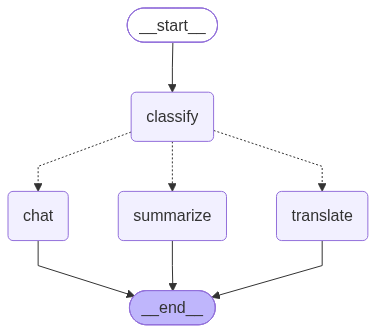

In [9]:
display(router_graph)

In [10]:
for text in ["'오늘 날씨가 정말 좋네요' 를 영어로 번역해줘",
             "다음 글을 요약해줘: 랭그래프는 상태 기반 그래프로 에이전트의 흐름을 설계하는 라이브러리이다. 분기와 반복, 병렬 실행과 사람 개입을 지원한다.",
             "오늘 점심 뭐 먹을까?"]:
    print(f"\n🧑 {text[:40]}...")
    print("🤖", router_graph.invoke({"user_input": text})["answer"])


🧑 '오늘 날씨가 정말 좋네요' 를 영어로 번역해줘...
   🧭 분류 결과: translate
🤖 "The weather is really nice today."

🧑 다음 글을 요약해줘: 랭그래프는 상태 기반 그래프로 에이전트의 흐름을 설...
   🧭 분류 결과: summarize
🤖 랭그래프는 상태 기반 그래프를 통해 에이전트의 흐름을 설계하며, 분기, 반복, 병렬 실행 및 사람 개입을 지원하는 라이브러리이다.

🧑 오늘 점심 뭐 먹을까?...
   🧭 분류 결과: chat
🤖 김밥 어때? 간편하고 맛있어!


**📝 정리** — LLM이 의도를 translate / summarize / chat 중 하나로만 골랐고(`Literal`), 그 값이 곧 다음 노드 이름이 됐다.

- `classify` 는 **분류만** 하고(상태에 `intent` 기록), 실제 분기는 `route_by_intent` 가 합니다. 역할이 깔끔하게 분리됩니다.
- `Literal["translate", "summarize", "chat"]` 으로 LLM 출력을 **세 값 중 하나로 강제**했기 때문에 라우팅 함수가 **예외 없이 안전**합니다. (자유 텍스트로 받으면 `"번역이요"` 같은 엉뚱한 값이 나와 에러가 날 수 있어요)
- 전문 노드마다 **프롬프트·모델·도구를 다르게** 구성할 수 있다는 것이 라우터 패턴의 큰 장점입니다.

## 🌳 14장. 도구 사용 에이전트 (ReAct) : `ToolNode` · `tools_condition`

### 📖 이론

진짜 "에이전트"는 **도구를 쓰고, 그 결과를 보고, 다시 생각하는 루프**입니다. 7장에서 배운 **사이클**이 여기서 빛을 발합니다.

```
          ┌──────────────────────────────────┐
          ▼                                  │
 START ─▶ 🤖 agent ──(tool_calls 있음)──▶ 🔧 tools
          │  (LLM 이 도구 호출을 요청)          (ToolNode 가 실행)
          │
          └──(tool_calls 없음 = 최종 답변)──▶ END
```

#### 구성 부품 3가지

| 부품 | 역할 |
|------|------|
| `llm.bind_tools(tools)` | LLM 에게 "이런 도구가 있어" 알려 줌 → 응답에 **`tool_calls`** 가 담겨 옴 |
| **`ToolNode(tools)`** | 마지막 AI 메시지의 `tool_calls` 를 **실행**하고 `ToolMessage` 로 결과를 State 에 추가 (예외 처리 포함) |
| **`tools_condition`** | 미리 만들어진 **라우팅 함수**: 마지막 메시지에 `tool_calls` 가 있으면 `"tools"`, 없으면 `END` |

<br>

> 📌 LangChain 으로 직접 짠 `for` 루프(도구 호출 → 실행 → 반복)가 **그래프의 사이클 하나**로 바뀐 것입니다.
> 🎁 LangChain 1.x 의 `create_agent` 는 바로 이 구조를 한 줄로 만들어 주는 함수입니다.

In [11]:
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition

@tool
def get_weather(city: str) -> str:
    """도시의 현재 날씨를 알려준다.

    Args:
        city: 날씨를 알고 싶은 도시 이름 (예: 서울)
    """
    fake = {"서울": "맑음, 18도", "부산": "흐림, 21도", "제주": "비, 19도"}
    return fake.get(city, f"{city} 날씨 정보 없음")

@tool
def multiply(a: int, b: int) -> int:
    """두 정수를 곱한다.

    Args:
        a: 첫 번째 수
        b: 두 번째 수
    """
    return a * b

tools = [get_weather, multiply]
llm_with_tools = llm.bind_tools(tools)                  # 👈 LLM 에게 도구 목록 알려주기

def build_agent(checkpointer=None):
    """도구 사용 에이전트 그래프를 만든다 (15장에서 체크포인터를 붙여 재사용)"""
    def agent(state: MessagesState) -> dict:
        system = SystemMessage("당신은 도구를 활용하는 도우미입니다. 한국어로 짧게 답하세요.")
        return {"messages": [llm_with_tools.invoke([system] + state["messages"])]}

    b = StateGraph(MessagesState)
    b.add_node("agent", agent)
    b.add_node("tools", ToolNode(tools))                # 👈 도구 실행 전담 노드
    
    b.add_edge(START, "agent")
    b.add_conditional_edges("agent", tools_condition)   # 👈 tool_calls 있으면 "tools", 없으면 END
    b.add_edge("tools", "agent")                        # 👈 도구 실행 후 다시 agent 로 (사이클!)
    return b.compile(checkpointer=checkpointer)

agent_graph = build_agent()

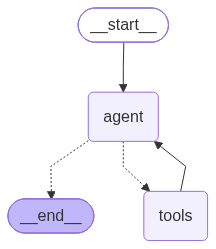

In [12]:

display(agent_graph)

### ▶️ 실행하고 메시지 흐름 관찰하기

`messages` 에 **누가 어떤 순서로** 쌓이는지 보세요. 이것이 ReAct(Reason + Act) 의 실체입니다.

| 메시지 | 의미 |
|--------|------|
| `Human` | 사용자 질문 |
| `AI (tool_calls)` | LLM 의 **행동 요청** ("get_weather(서울) 호출해줘") |
| `Tool` | 도구 **실행 결과** (Observation) |
| `AI` | 결과를 바탕으로 한 **최종 답변** |

In [13]:
for question in ["서울 날씨 알려줘", "12 곱하기 7은 얼마야?"]:
    print("=" * 70)
    result = agent_graph.invoke({"messages": [HumanMessage(question)]})
    for m in result["messages"]:
        m.pretty_print()

================================ Human Message =================================

서울 날씨 알려줘
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_u8nzNAe0XfhSaF9rmAy2eWa4)
 Call ID: call_u8nzNAe0XfhSaF9rmAy2eWa4
  Args:
    city: 서울
================================= Tool Message =================================
Name: get_weather

맑음, 18도
================================== Ai Message ==================================

서울의 날씨는 맑고, 기온은 18도입니다.
================================ Human Message =================================

12 곱하기 7은 얼마야?
================================== Ai Message ==================================
Tool Calls:
  multiply (call_nKfmWeM3I0Voy5UBezUQua26)
 Call ID: call_nKfmWeM3I0Voy5UBezUQua26
  Args:
    a: 12
    b: 7
================================= Tool Message =================================
Name: multiply

84
================================== Ai Message ==================================

12 곱하기 7은 84

**📝 정리** — Human → AI(tool_calls) → Tool → AI 순서로 쌓였다. `get_weather(서울)` → 맑음 18도, `multiply(12, 7)` → 84.

- `add_conditional_edges("agent", tools_condition)` — 라우팅 함수를 **직접 짤 필요 없이** 미리 만들어진 `tools_condition` 을 쓴 예입니다.
- `add_edge("tools", "agent")` 가 **사이클**을 만듭니다. 도구를 여러 번 써야 하는 질문이면 이 루프가 여러 바퀴 돕니다.
- 도구가 **필요 없는 질문**("안녕!")이면 `tool_calls` 가 없으므로 `agent → END` 로 바로 끝납니다.

### ⚠️ 자주 하는 실수
- `llm.bind_tools` 가 아닌 `llm` 을 노드에서 호출 → 모델이 **도구 존재를 몰라서** 호출 요청이 안 나옵니다.
- `add_edge("tools", "agent")` 를 빼먹음 → 도구 결과를 받은 LLM 이 **최종 답변을 못 하고** 그래프가 도구 노드에서 끝나 버립니다.

## 🌲 15장. 메모리 : 체크포인터(Checkpointer)와 `thread_id`

### 📖 이론

12장에서 확인했듯 그래프는 **호출 간에 기억이 없습니다.** 대화를 이어가려면 **State 를 저장**해야 합니다.
LangGraph 는 이를 **체크포인터**로 해결합니다.

```
 graph = builder.compile(checkpointer=InMemorySaver())      # ① 저장소를 붙이고
 graph.invoke(입력, config={"configurable": {"thread_id": "또치-대화1"}})   # ② 대화방 ID 를 넘기면 끝!
```

#### 🧠 어떻게 동작하나?

```
 invoke(thread_id="A")  ─▶ ① 저장소에서 thread A 의 마지막 State 를 불러옴
                            ② 새 입력을 반영해 그래프 실행
                            ③ 슈퍼스텝이 끝날 때마다 State 를 "체크포인트"로 저장
 invoke(thread_id="A")  ─▶ 앞 대화가 이어진 State 에서 시작!
 invoke(thread_id="B")  ─▶ 완전히 별개의 새 대화
```

| 개념 | 설명 |
|------|------|
| **체크포인트** | 슈퍼스텝마다 저장되는 **State 스냅샷** |
| **thread** | 체크포인트가 이어지는 **하나의 대화/작업 줄기** (`thread_id` 로 구분) |
| `InMemorySaver` | 메모리에 저장 (실습용, 프로그램 종료하면 사라짐) |
| `SqliteSaver` / `PostgresSaver` | **영속 저장** (운영용, 별도 패키지 `langgraph-checkpoint-sqlite` 등) |

#### 💡 체크포인터가 주는 선물
**멀티턴 메모리** · **사람 개입 후 재개(17장)** · **실패 지점부터 재시작** · **과거 시점 조회/되감기** — 전부 같은 기반 위에서 동작합니다.

> 📌 입력은 **"새 메시지만"** 넘기세요. 이전 대화는 체크포인터가 불러와서 `add_messages` 로 이어 붙입니다.

In [14]:
from langgraph.checkpoint.memory import InMemorySaver

memory_agent = build_agent(checkpointer=InMemorySaver())     # 14장의 에이전트에 체크포인터만 추가!

config_a = {"configurable": {"thread_id": "unico-1"}}      # 유니코의 대화방

memory_agent.invoke({"messages": [HumanMessage("내 이름은 유니코야. 기억해줘!")]}, config_a)
result = memory_agent.invoke({"messages": [HumanMessage("내 이름이 뭐였지?")]}, config_a)     # 새 메시지만 전달
print("🤖 (같은 thread) :", result["messages"][-1].content)

config_b = {"configurable": {"thread_id": "gildong-1"}}     # 다른 대화방
result = memory_agent.invoke({"messages": [HumanMessage("내 이름이 뭐였지?")]}, config_b)
print("🤖 (다른 thread) :", result["messages"][-1].content)

🤖 (같은 thread) : 유니코님이세요!
🤖 (다른 thread) : 죄송하지만, 당신의 이름을 알 수 없습니다.


**📝 정리** — 그래프 코드는 그대로 두고 `compile(checkpointer=...)`만 추가했다. 같은 thread는 이름을 기억, 다른 thread는 모름.

- 같은 `thread_id` 에서는 앞 대화가 이어지고, **다른 `thread_id` 는 서로 완전히 독립**입니다. (사용자별로 `thread_id` 를 다르게 부여하면 멀티 유저 챗봇 완성!)
- 그래프 정의 코드는 **한 줄도 바꾸지 않고** `compile(checkpointer=...)` 만 추가했습니다.

### 🔎 저장된 State 들여다보기 — `get_state` · `get_state_history`

In [15]:
snapshot = memory_agent.get_state(config_a)           # 현재(최신) 체크포인트
print("📚 저장된 메시지 수 :", len(snapshot.values["messages"]))
print("➡️  다음 실행할 노드 :", snapshot.next, " ← 비어 있으면 그래프가 끝난 상태")
print()

history = list(memory_agent.get_state_history(config_a))      # 최신 → 과거 순서
print(f"🕰️ 체크포인트 총 {len(history)}개 (슈퍼스텝마다 1개씩 저장됨)")
print(f"{'#':>2} | {'다음 노드':<14} | 메시지 수")
for i, snap in enumerate(reversed(history)):                 # 과거 → 최신 순으로 출력
    print(f"{i:>2} | {str(snap.next):<14} | {len(snap.values.get('messages', []))}")

📚 저장된 메시지 수 : 4
➡️  다음 실행할 노드 : ()  ← 비어 있으면 그래프가 끝난 상태

🕰️ 체크포인트 총 6개 (슈퍼스텝마다 1개씩 저장됨)
 # | 다음 노드          | 메시지 수
 0 | ('__start__',) | 0
 1 | ('agent',)     | 1
 2 | ()             | 2
 3 | ('__start__',) | 2
 4 | ('agent',)     | 3
 5 | ()             | 4


**📝 정리** — 체크포인트 6개 = 턴마다 `('__start__',)` → `('agent',)` → `()` 3개씩. `next`가 비어 있으면 그래프가 끝난 상태.

In [16]:
snapshot.values["messages"]

[HumanMessage(content='내 이름은 유니코야. 기억해줘!', additional_kwargs={}, response_metadata={}, id='170ec7f9-f3cc-4c37-b305-b2f1d47cb6b9'),
 AIMessage(content='알겠어요, 유니코님! 기억할게요.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 135, 'total_tokens': 150, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9017dcc87e', 'id': 'chatcmpl-EeV16eM9w82xBfOsLN3zvHuSwikSU', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18a43-b645-7ad1-bc69-93f05a7a25fc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 135, 'output_tokens': 15, 'total_tokens':

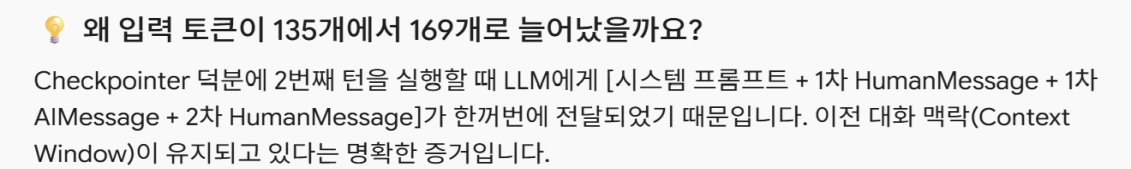

In [17]:
list(memory_agent.get_state_history(config_a))

[StateSnapshot(values={'messages': [HumanMessage(content='내 이름은 유니코야. 기억해줘!', additional_kwargs={}, response_metadata={}, id='170ec7f9-f3cc-4c37-b305-b2f1d47cb6b9'), AIMessage(content='알겠어요, 유니코님! 기억할게요.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 135, 'total_tokens': 150, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9017dcc87e', 'id': 'chatcmpl-EeV16eM9w82xBfOsLN3zvHuSwikSU', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18a43-b645-7ad1-bc69-93f05a7a25fc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 135, 'o

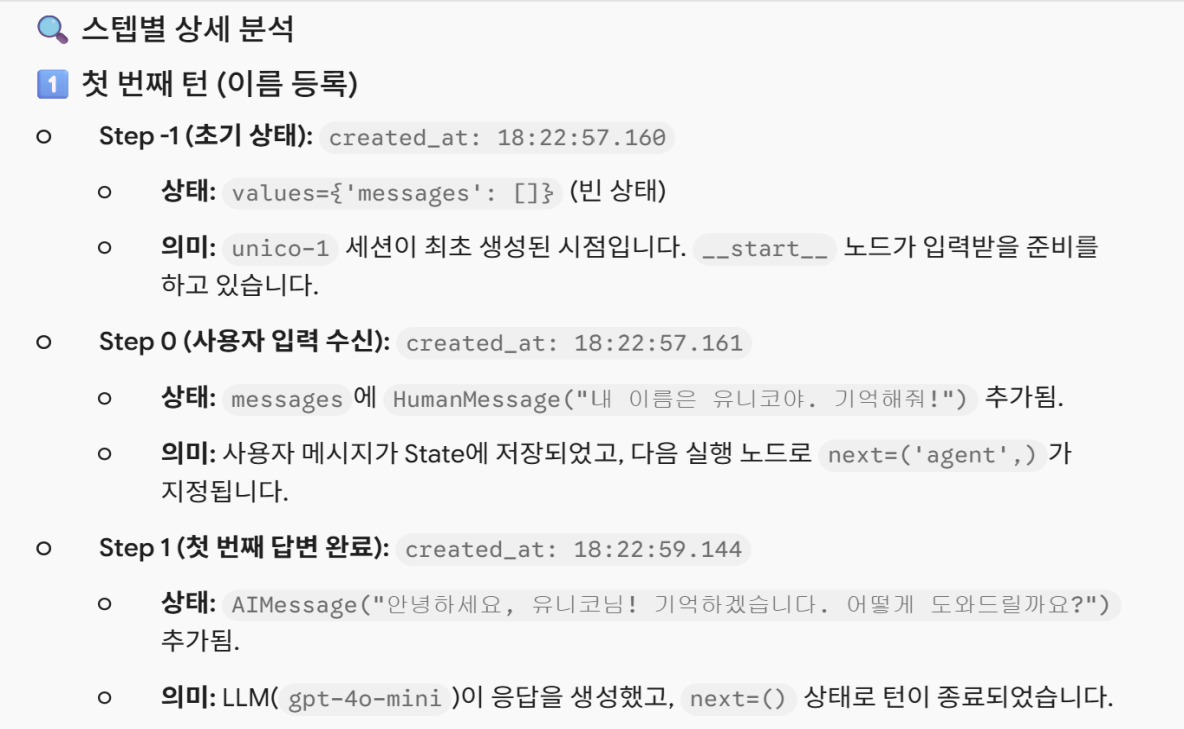

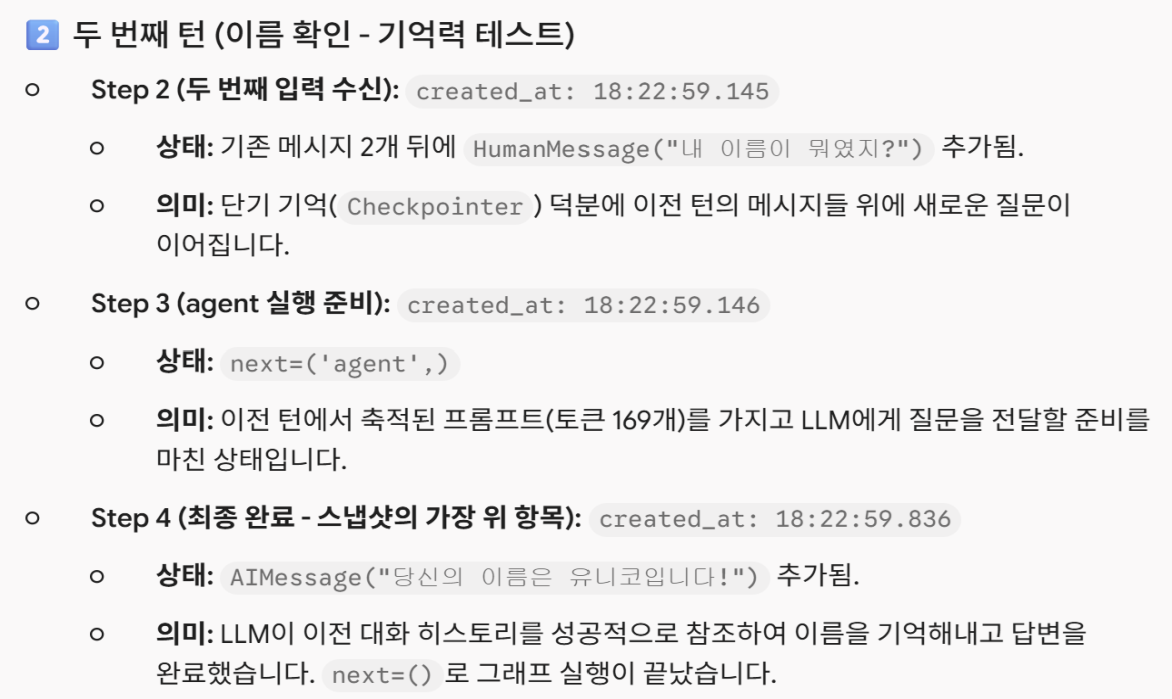

- `get_state(config)` : 해당 thread 의 **최신 State** 와 **다음에 실행될 노드**(`next`)를 확인합니다.
- `get_state_history(config)` : 모든 체크포인트의 **타임라인**. 과거 시점으로 되돌아가 **다시 실행(replay)** 하거나 **분기(fork)** 할 수도 있습니다. (디버깅에 강력!)
- 표의 `('__start__',)` 는 **새 입력이 들어온 직후**의 체크포인트이고, `('agent',)` 는 "다음에 agent 가 실행될 차례"라는 뜻입니다. 대화가 두 번 있었으므로 **같은 모양이 두 묶음** 보이죠?
- `next` 가 비어 있지 않으면 그래프가 **중간에 멈춰 있다**는 뜻입니다. → 17장에서 활용합니다.

## 🌲 16장. 스트리밍 — `stream_mode` 5가지

### 📖 이론

`invoke` 는 **끝날 때까지** 기다려야 합니다. 챗 UI 에서 **진행 상황을 보여 주거나 글자가 타자 치듯** 나오게 하려면 `stream` 을 씁니다.
**"무엇을 흘려보낼지"** 를 `stream_mode` 로 고릅니다.

| `stream_mode` | 흘려보내는 내용 | 대표 용도 |
|---------------|-----------------|-----------|
| `"values"` | 매 단계 후 **전체 State** | 디버깅, 전체 상태 추적 |
| `"updates"` | 노드가 끝날 때마다 **그 노드가 바꾼 부분**만 | 진행 상황 표시 (가장 많이 씀) |
| `"messages"` | **LLM 토큰** 하나하나 + 메타데이터 | 챗 UI 타자 효과 |
| `"custom"` | 노드 안에서 `get_stream_writer()` 로 보낸 **임의 데이터** | 진행률(%) 표시 |
| `"debug"` | 실행의 모든 세부 이벤트 | 심층 디버깅 |

<br>

> 📌 리스트로 여러 모드를 동시에 요청할 수 있습니다: `stream_mode=["updates", "custom"]` → `(모드이름, 데이터)` 튜플이 흘러나옵니다.

In [18]:
from langgraph.config import get_stream_writer

class JobState(TypedDict):
    total: int

# ✍️ 노드 안에서 get_stream_writer() 로 '진행 상황'을 직접 흘려보내기
def heavy_job(state: JobState) -> dict:
    writer = get_stream_writer()
    total = 0
    for i in range(1, 4):
        total += i
        writer({"progress": f"{i}/3 단계 완료"})            # 👈 custom 이벤트
    return {"total": total}

builder = StateGraph(JobState)
builder.add_node("heavy_job", heavy_job)

builder.add_edge(START, "heavy_job")
builder.add_edge("heavy_job", END)
job_graph = builder.compile()

In [19]:
print("① values  :", list(job_graph.stream({"total": 0}, stream_mode="values")))
print("② updates :", list(job_graph.stream({"total": 0}, stream_mode="updates")))
print("③ custom  :", list(job_graph.stream({"total": 0}, stream_mode="custom")))
print("④ 동시 요청:", list(job_graph.stream({"total": 0}, stream_mode=["updates", "custom"])))

① values  : [{'total': 0}, {'total': 6}]
② updates : [{'heavy_job': {'total': 6}}]
③ custom  : [{'progress': '1/3 단계 완료'}, {'progress': '2/3 단계 완료'}, {'progress': '3/3 단계 완료'}]
④ 동시 요청: [('custom', {'progress': '1/3 단계 완료'}), ('custom', {'progress': '2/3 단계 완료'}), ('custom', {'progress': '3/3 단계 완료'}), ('updates', {'heavy_job': {'total': 6}})]


**📝 정리** — values는 전체 State, updates는 바뀐 부분, custom은 노드 실행 **도중** 보낸 진행률. 여러 모드를 리스트로 주면 `(모드, 데이터)` 튜플로 나온다.

- `values` 는 **전체 State** 를, `updates` 는 **바뀐 부분**만 보여 줍니다. (같은 실행인데 정보량이 다르죠)
- `custom` 은 **노드가 실행되는 도중**에 보낸 데이터라, 오래 걸리는 작업의 **진행률 표시**에 딱 맞습니다.
- 모드를 리스트로 주면 `("updates", {...})`, `("custom", {...})` 처럼 **어떤 모드의 데이터인지 이름표**가 붙습니다.

### 🔤 `messages` 모드 — LLM 토큰 스트리밍

14장의 에이전트로 **답변이 글자 단위로 흘러나오게** 해 봅니다. `(토큰조각, 메타데이터)` 가 흘러나오고, 메타데이터의 `langgraph_node` 로 **어느 노드의 토큰인지** 알 수 있습니다.

In [20]:
config_s = {"configurable": {"thread_id": "stream-demo"}}

print("🤖 ", end="")
for chunk, meta in memory_agent.stream(
    {"messages": [HumanMessage("부산 날씨 알려주고, 우산이 필요한지도 말해줘")]},
    config_s,
    stream_mode="messages",
):
    # agent 노드가 만든 '텍스트 토큰'만 출력 (도구 호출 조각/도구 결과는 건너뜀)
    if meta["langgraph_node"] == "agent" and chunk.content:
        print(chunk.content, end="@", flush=True)
print()

🤖 부@산@의@ 현재@ 날@씨@는@ 흐@림@이며@,@ 기@온@은@ @21@도@입니다@.@ 우@산@이@ 필요@할@ 수@ 있습니다@.@


**📝 정리** — `messages` 모드로 최종 답이 토큰 단위로 나왔다(`@`로 구분). 도구 호출 단계는 텍스트 토큰이 없어 조용히 지나간다.

- 도구를 호출하는 단계에서는 텍스트 토큰이 없어 **조용히 지나가고**, 도구 결과를 받은 뒤의 **최종 답변이 글자 단위로** 출력됩니다.
- `if meta["langgraph_node"] == "agent"` 필터를 빼면 도구 결과(`ToolMessage`) 등 **다른 노드의 출력도** 섞여 나옵니다. 용도에 맞게 거르세요.

## 🌲 17장. Human-in-the-loop : `interrupt` 와 `Command(resume=...)`

### 📖 이론

송금·삭제·메일 발송처럼 **되돌릴 수 없는 행동** 앞에서는 에이전트가 멈추고 **사람의 승인**을 받아야 합니다.
LangGraph 는 **그래프를 "일시정지" 했다가 "이어서 재개"** 하는 기능을 기본 제공합니다.

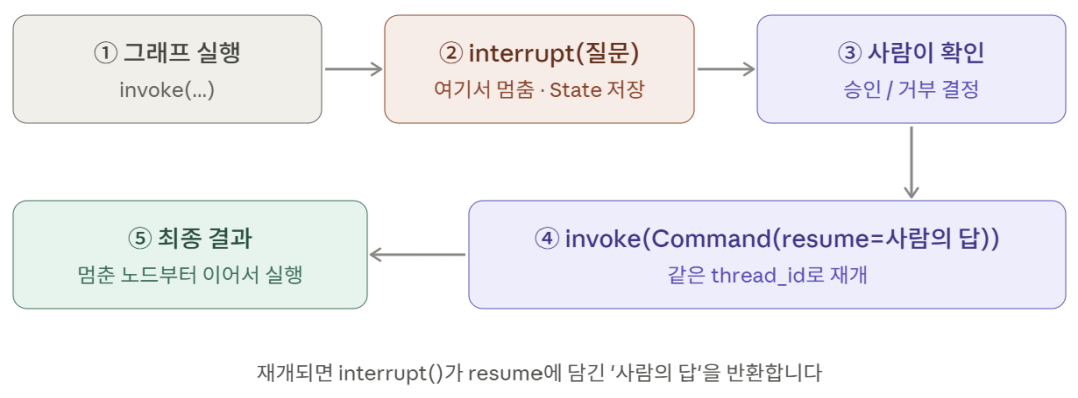

#### 📌 필수 조건과 핵심 규칙

| # | 규칙 | 이유 |
|:-:|------|------|
| 1 | **체크포인터가 필수** | 멈춘 지점의 State 를 저장해야 하므로 |
| 2 | **`thread_id` 필수** | 어떤 대화를 재개할지 식별 |
| 3 | `interrupt(값)` 의 **값**은 호출자에게 전달됨 | `result["__interrupt__"]` 로 확인 |
| 4 | 재개는 `Command(resume=값)` | 그 **값**이 `interrupt()` 의 **반환값**이 됨 |
| 5 | ⚠️ **재개 시 노드가 처음부터 다시 실행됨** | `interrupt()` **앞**에 부작용(결제·DB 쓰기)을 두면 **두 번** 일어남! |

<br>

> 🔑 5번이 가장 중요합니다. 아래 실습에서 `print` 가 **두 번** 찍히는 것을 직접 눈으로 확인합니다.

In [21]:
from langgraph.types import interrupt, Command

class TransferState(TypedDict):
    to: str
    amount: int
    result: str

def prepare(state: TransferState) -> dict:
    print(f"   ▶ [prepare] {state['to']}님께 {state['amount']:,}원 송금 준비")
    return {}

def approval(state: TransferState) -> Command[Literal["execute", "cancel"]]:
    print("   ▶ [approval] 노드 시작  ← 이 줄이 몇 번 출력되는지 지켜보세요!")
    # 🛑 여기서 그래프가 멈춘다. 아래 dict 가 호출자에게 전달되고, 재개되면 사람의 답이 approved 에 담긴다.
    approved = interrupt({"question": f"{state['to']}님께 {state['amount']:,}원을 송금할까요?"})
    return Command(goto="execute" if approved else "cancel")

def execute(state: TransferState) -> dict:
    print("   ▶ [execute] 💸 송금 실행!")
    return {"result": "송금 완료"}

def cancel(state: TransferState) -> dict:
    print("   ▶ [cancel] 송금 취소")
    return {"result": "송금 취소됨"}

builder = StateGraph(TransferState)
builder.add_node("prepare", prepare)
builder.add_node("approval", approval)
builder.add_node("execute", execute)
builder.add_node("cancel", cancel)

builder.add_edge(START, "prepare")
builder.add_edge("prepare", "approval")
builder.add_edge("execute", END)
builder.add_edge("cancel", END)
transfer_graph = builder.compile(checkpointer=InMemorySaver())          # 👈 체크포인터 필수!

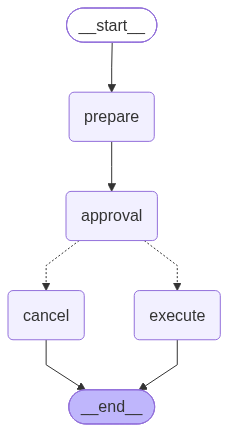

In [22]:
show_graph(transfer_graph)

### ▶️ ① 승인 시나리오

1. 첫 `invoke` → `approval` 에서 **멈춤**
2. 사람(우리)이 질문을 확인
3. `Command(resume=True)` 로 **재개**

In [23]:
config = {"configurable": {"thread_id": "transfer-1"}}

print("① 첫 번째 invoke")
result = transfer_graph.invoke({"to": "유니코", "amount": 50000, "result": ""}, config)

print("\n⏸️  멈췄다!")
print("   result 에 담긴 __interrupt__ :", result["__interrupt__"][0].value)
print("   다음 실행 노드(next)         :", transfer_graph.get_state(config).next)

print("\n② 사람이 '승인' → 재개")
result = transfer_graph.invoke(Command(resume=True), config)          # 👈 같은 thread_id 로 재개
print("\n✅ 최종 결과:", result["result"])

① 첫 번째 invoke
   ▶ [prepare] 유니코님께 50,000원 송금 준비
   ▶ [approval] 노드 시작  ← 이 줄이 몇 번 출력되는지 지켜보세요!

⏸️  멈췄다!
   result 에 담긴 __interrupt__ : {'question': '유니코님께 50,000원을 송금할까요?'}
   다음 실행 노드(next)         : ('approval',)

② 사람이 '승인' → 재개
   ▶ [approval] 노드 시작  ← 이 줄이 몇 번 출력되는지 지켜보세요!
   ▶ [execute] 💸 송금 실행!

✅ 최종 결과: 송금 완료


**📝 정리** — `[approval] 노드 시작`이 **두 번** 출력됐다. 재개하면 노드가 처음부터 다시 실행되고 이번엔 `interrupt()`가 사람의 답(True)을 돌려준다. 그래서 interrupt 앞에는 부작용 있는 코드를 두지 않는다.

- `[approval] 노드 시작` 이 **두 번** 출력되었죠? 첫 실행 때 한 번, **재개되면서 노드가 처음부터 다시** 실행되어 또 한 번입니다.\
  재개 때는 `interrupt()` 가 멈추지 않고 **`True`(사람의 답)를 반환**하며 그대로 통과합니다.
- 그래서 **`interrupt()` 앞에는 "여러 번 실행돼도 안전한 코드"만** 둬야 합니다. 송금(`execute`)처럼 위험한 일은 **`interrupt()` 뒤의 별도 노드**에 두었죠.
- `prepare` 는 `interrupt()` 이전 **다른 노드**라서 다시 실행되지 않았습니다.

### ▶️ ② 거부 시나리오

In [24]:
config2 = {"configurable": {"thread_id": "transfer-2"}}

transfer_graph.invoke({"to": "마이콜", "amount": 1_000_000, "result": ""}, config2)       # 멈춤
result = transfer_graph.invoke(Command(resume=False), config2)                          # 사람이 '거부'
print("\n🛑 최종 결과:", result["result"])

   ▶ [prepare] 마이콜님께 1,000,000원 송금 준비
   ▶ [approval] 노드 시작  ← 이 줄이 몇 번 출력되는지 지켜보세요!
   ▶ [approval] 노드 시작  ← 이 줄이 몇 번 출력되는지 지켜보세요!
   ▶ [cancel] 송금 취소

🛑 최종 결과: 송금 취소됨


**📝 정리** — 거부(`resume=False`)도 approval이 두 번 실행된 뒤 cancel로 갔다.

### 🧰 정적 중단점 `interrupt_before` / `interrupt_after`

`interrupt()` 를 노드 **안에** 심는 방식 외에, `compile` 때 **"이 노드 실행 직전에 무조건 멈춰라"** 라고 지정할 수도 있습니다.
재개는 `invoke(None, config)` 입니다. (입력 없이 이어서 실행)

| | `interrupt()` (동적) | `interrupt_before=[...]` (정적) |
|---|---|---|
| 위치 | 노드 **코드 안** | `compile` 옵션 |
| 사람에게 **값 전달** | ✅ (질문, 초안 등) | ❌ (State 만 확인) |
| 사람의 **답을 코드로 받기** | ✅ (`interrupt()` 반환값) | ❌ (State 를 수정하거나 그냥 진행) |
| 조건부 중단 | ✅ (`if` 로 호출 여부 결정) | ❌ (항상 멈춤) |
| 용도 | **실무 권장** | 간단한 디버깅 / 단계별 확인 |

In [25]:
class StepState(TypedDict):
    x: int

b = StateGraph(StepState)
b.add_node("add_one", lambda s: {"x": s["x"] + 1})
b.add_node("times_ten", lambda s: {"x": s["x"] * 10})

b.add_edge(START, "add_one")
b.add_edge("add_one", "times_ten")
b.add_edge("times_ten", END)
step_graph = b.compile(checkpointer=InMemorySaver(), interrupt_before=["times_ten"])   # times_ten 직전에 멈춰라

In [26]:
cfg = {"configurable": {"thread_id": "step-1"}}

print("① 실행 →", step_graph.invoke({"x": 1}, cfg), "  (add_one 까지만 실행됨)")
print("   다음 노드:", step_graph.get_state(cfg).next)
print("② 재개  →", step_graph.invoke(None, cfg), "  (None 을 넣으면 이어서 실행)")

① 실행 → {'x': 2}   (add_one 까지만 실행됨)
   다음 노드: ('times_ten',)
② 재개  → {'x': 20}   (None 을 넣으면 이어서 실행)


**📝 정리** — `interrupt_before=["times_ten"]`: add_one까지만 실행(x=2)하고 멈춤 → `invoke(None, cfg)`로 재개(x=20).

## 🌲 18장. 에러 처리 — `RetryPolicy`

### 📖 이론

외부 API·네트워크 호출은 **가끔 실패**합니다. 그때마다 그래프 전체를 처음부터 다시 돌리는 건 낭비죠.
노드에 **재시도 정책(`RetryPolicy`)** 을 붙이면, **그 노드만** 자동으로 다시 시도합니다.

```python
builder.add_node(
    "call_api", call_api,
    retry_policy=RetryPolicy(max_attempts=3, initial_interval=0.5, retry_on=ConnectionError),
)
```

| 파라미터 | 의미 |
|----------|------|
| `max_attempts` | 최대 시도 횟수 (처음 시도 포함) |
| `initial_interval` | 첫 재시도까지 대기 시간(초) |
| `backoff_factor` | 재시도마다 대기 시간을 몇 배로 늘릴지 (지수 백오프) |
| `retry_on` | **어떤 예외일 때만** 재시도할지 (예외 클래스 또는 판별 함수) |

<br>

> 💡 `retry_on` 을 지정하지 않으면 **일시적 오류로 보기 어려운 예외**(`ValueError`, `TypeError` 등 코드 버그 성격)는 재시도하지 않는 합리적인 기본값이 적용됩니다. 의도를 분명히 하려면 직접 지정하세요.
> 🧱 재시도해도 안 되는 오류는 노드 안에서 `try/except` 로 **대체 응답(fallback)** 을 반환하는 방식으로 처리할 수도 있습니다.

In [27]:
from langgraph.types import RetryPolicy

attempts = {"count": 0}          # 몇 번 시도했는지 세기 위한 카운터

class ApiState(TypedDict):
    data: str

def flaky_api(state: ApiState) -> dict:
    attempts["count"] += 1
    print(f"   ▶ API 호출 시도 #{attempts['count']}")
    if attempts["count"] < 3:                                   # 처음 두 번은 실패하도록 연출
        raise ConnectionError("일시적인 네트워크 오류")
    return {"data": "✅ 데이터 수신 성공"}

builder = StateGraph(ApiState)
builder.add_node(
    "flaky_api", flaky_api,
    retry_policy=RetryPolicy(max_attempts=3, initial_interval=0.1, retry_on=ConnectionError),   # 👈 최대 3번
)
builder.add_edge(START, "flaky_api")
builder.add_edge("flaky_api", END)
retry_graph = builder.compile()

In [28]:
print(retry_graph.invoke({"data": ""}))

# ── 시도 횟수보다 오래 실패하면? → 마지막 예외가 그대로 전달됨 ──
attempts["count"] = -10          # 앞으로 한참 동안 계속 실패하게 만들기
try:
    retry_graph.invoke({"data": ""})
except ConnectionError as e:
    print("\n❌ 3번 모두 실패 → 예외 전달:", e)

   ▶ API 호출 시도 #1
   ▶ API 호출 시도 #2
   ▶ API 호출 시도 #3
{'data': '✅ 데이터 수신 성공'}
   ▶ API 호출 시도 #-9
   ▶ API 호출 시도 #-8
   ▶ API 호출 시도 #-7

❌ 3번 모두 실패 → 예외 전달: 일시적인 네트워크 오류


**📝 정리** — 1·2번째 시도 실패 → 3번째 성공(호출은 한 번). 계속 실패하면 3번 시도 후 마지막 예외가 그대로 올라온다.

- 1·2번째 시도는 실패했지만 **자동으로 재시도**되어 3번째에 성공했습니다. 호출하는 쪽에서는 **한 번 `invoke`** 했을 뿐입니다.
- `max_attempts` 를 모두 소진하면 **마지막 예외가 그대로** 올라옵니다. → 호출자가 `try/except` 로 처리하세요.
- 같은 정책을 **LLM 호출 노드**에 붙이면 일시적인 API 오류(레이트 리밋 등)에 훨씬 튼튼해집니다.

## 🌲 19장. 서브그래프 — 그래프 안의 그래프

### 📖 이론

그래프가 커지면 **덩어리별로 나눠** 관리하고 싶어집니다. 컴파일된 그래프를 **다른 그래프의 노드로** 넣을 수 있습니다.

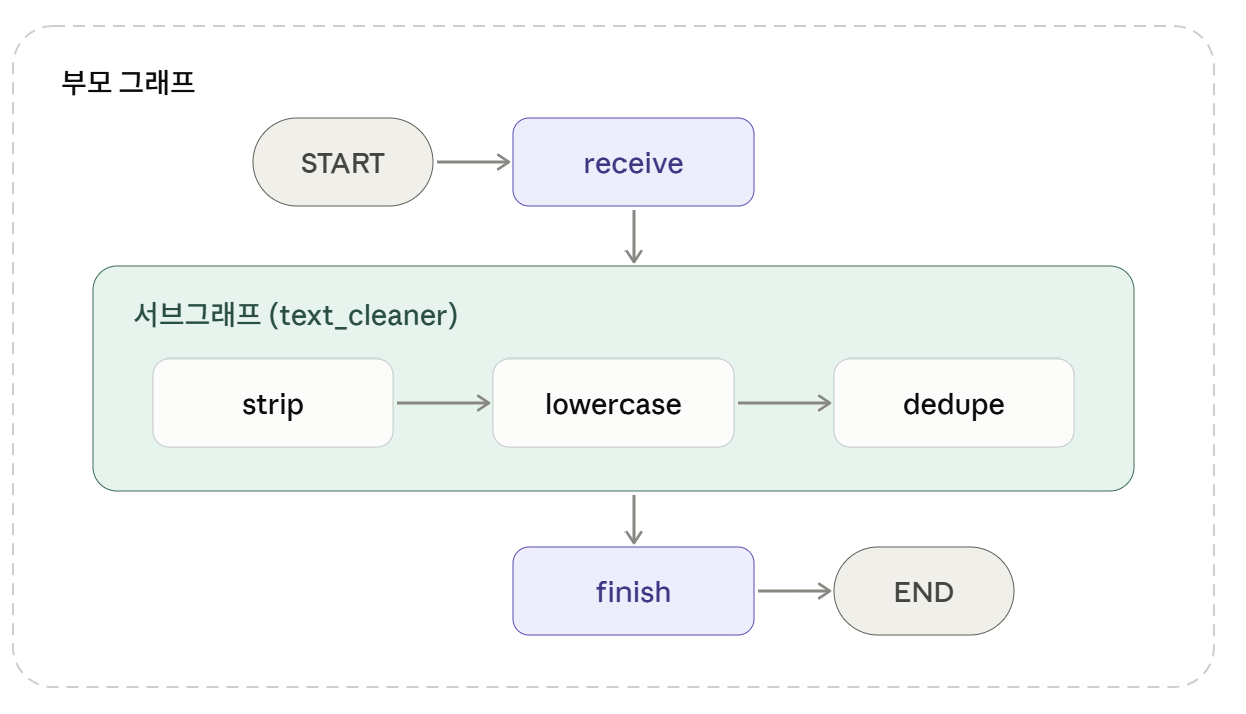

| 장점 | 설명 |
|------|------|
| ♻️ **재사용** | 같은 서브그래프를 여러 부모에서 사용 |
| 🧪 **독립 테스트** | 서브그래프만 따로 `invoke` 해 검증 |
| 👥 **팀 분업** | 팀마다 서브그래프를 만들어 조립 (멀티 에이전트의 기초) |

#### 연결 방식 2가지

| 방식 | 조건 | 방법 |
|------|------|------|
| **① 노드로 직접 추가** | 부모와 서브그래프의 **State 키가 겹칠 때** | `builder.add_node("이름", 서브그래프)` |
| **② 함수로 감싸서 호출** | State 모양이 **다를 때** | 노드 함수 안에서 `서브그래프.invoke(변환한 입력)` 후 결과를 변환해 반환 |

In [29]:
# ───── 서브그래프: 텍스트 정리기 (strip → lowercase) ─────
class CleanerState(TypedDict):
    text: str

def strip_text(state: CleanerState) -> dict:
    return {"text": state["text"].strip()}

def lower_text(state: CleanerState) -> dict:
    return {"text": state["text"].lower()}

sb = StateGraph(CleanerState)
sb.add_node("strip_text", strip_text)
sb.add_node("lower_text", lower_text)

sb.add_edge(START, "strip_text")
sb.add_edge("strip_text", "lower_text")
sb.add_edge("lower_text", END)
cleaner = sb.compile()                                     # 👈 컴파일된 서브그래프

print("🧪 서브그래프 단독 테스트:", cleaner.invoke({"text": "  HeLLo  "}))

🧪 서브그래프 단독 테스트: {'text': 'hello'}


In [30]:
# ───── 부모 그래프: 서브그래프를 노드로 추가 (① State 키 'text' 가 겹침) ─────
class ParentState(TypedDict):
    text: str
    length: int

def finish(state: ParentState) -> dict:
    return {"length": len(state["text"])}

pb = StateGraph(ParentState)
pb.add_node("cleaner", cleaner)                            # 👈 그래프를 그대로 노드로!
pb.add_node("finish", finish)
pb.add_edge(START, "cleaner")
pb.add_edge("cleaner", "finish")
pb.add_edge("finish", END)
parent = pb.compile()

print("▶ 부모 그래프 실행:", parent.invoke({"text": "  LangGRAPH  ", "length": 0}))

▶ 부모 그래프 실행: {'text': 'langgraph', 'length': 9}


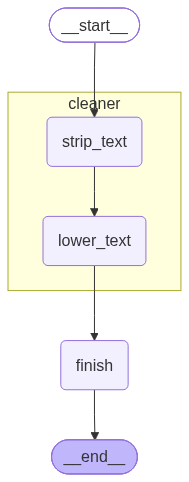

In [31]:
show_graph(parent, xray=True)                              # xray=True: 서브그래프 내부까지 펼쳐 보기

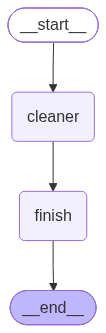

In [32]:
display(parent)

- `add_node("cleaner", cleaner)` — 컴파일된 그래프를 **그냥 노드처럼** 넣었습니다. 두 그래프가 `text` 키를 **공유**하므로 값이 자동으로 오갑니다.
- `show_graph(parent, xray=True)` 로 **서브그래프 내부 노드까지** 펼쳐서 볼 수 있습니다. (`xray=False` 면 `cleaner` 박스 하나로만 표시)
- 서브그래프의 내부 진행까지 스트리밍으로 보려면 `stream(..., subgraphs=True)` 를 씁니다.

### 🔀 ② State 모양이 다를 때: 함수로 감싸기

In [33]:
# 부모는 'raw' / 'clean_len' 이라는 다른 키를 쓴다 → 변환이 필요
class OtherParentState(TypedDict):
    raw: str
    clean_len: int

def call_cleaner(state: OtherParentState) -> dict:
    sub_result = cleaner.invoke({"text": state["raw"]})        # 입력을 서브그래프 모양으로 변환해서 호출
    return {"clean_len": len(sub_result["text"])}              # 결과를 부모 모양으로 변환해서 반환

ob = StateGraph(OtherParentState)
ob.add_node("call_cleaner", call_cleaner)

ob.add_edge(START, "call_cleaner")
ob.add_edge("call_cleaner", END)
print(ob.compile().invoke({"raw": "   Wrapped   ", "clean_len": 0}))

{'raw': '   Wrapped   ', 'clean_len': 7}


In [34]:
# 서브그래프 내부 진행까지 스트리밍해서 보기 (subgraphs=True)
print("\n📡 subgraphs=True 로 내부 진행 보기:")
for namespace, update in parent.stream({"text": "  ABC  ", "length": 0}, stream_mode="values", subgraphs=True):
    where = "부모" if namespace == () else "서브그래프 내부"
    print(f"   [{where}] {update}")


📡 subgraphs=True 로 내부 진행 보기:
   [부모] {'text': '  ABC  ', 'length': 0}
   [서브그래프 내부] {'text': '  ABC  '}
   [서브그래프 내부] {'text': 'ABC'}
   [서브그래프 내부] {'text': 'abc'}
   [부모] {'text': 'abc', 'length': 0}
   [부모] {'text': 'abc', 'length': 3}


**📝 정리** — `subgraphs=True`로 서브그래프 내부 진행(`'  ABC  '` → `'ABC'` → `'abc'`)까지 스트리밍했다.

## 🏁 20장. 종합 실습 — 사람 피드백을 반영하는 글쓰기 에이전트

### 📖 설계

지금까지 배운 것을 **하나로 합칩니다.** AI 가 초안을 쓰면 **사람이 검토**하고, 마음에 들 때까지 **피드백을 반영해 다시 쓰는** 에이전트입니다.

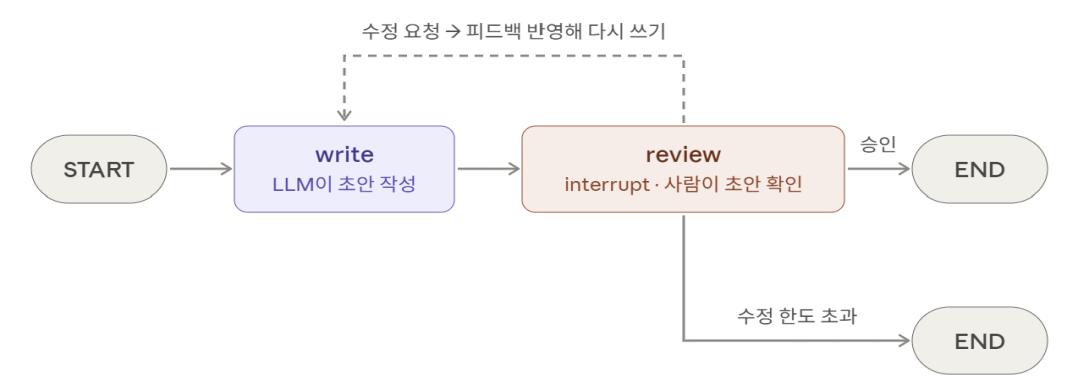

| 사용한 개념 | 어디에? |
|-------------|---------|
| **State** | `topic`, `draft`, `feedback`, `revisions` |
| **LLM 노드** (12장) | `write` — 초안 작성 / 피드백 반영 |
| **사이클** (7장) | `review → write` 로 되돌아가는 루프 + **횟수 제한** |
| **`Command`** (10장) | `review` 가 `goto` 로 다음 목적지 결정 |
| **`interrupt`** (17장) | `review` 에서 사람에게 초안을 보여 주고 답 받기 |
| **체크포인터** (15장) | 멈춘 상태 저장 → 재개 |

<br>

> 🛡️ **안전장치**: `MAX_REVISIONS`(최대 수정 횟수)를 State 의 `revisions` 카운터로 직접 제한합니다. LLM 이 끝없이 비용을 쓰는 것을 막는 습관!

In [35]:
MAX_REVISIONS = 3                    # 최대 작성 횟수 (초안 포함)

class WriterState(TypedDict):
    topic: str          # 글 주제
    draft: str          # 현재 초안
    feedback: str       # 사람의 수정 요청
    revisions: int      # 지금까지 쓴 횟수

# ✍️ LLM 이 쓰는 노드: 피드백이 있으면 반영해서 다시 쓰고, 없으면 첫 초안 작성
def write(state: WriterState) -> dict:
    if state.get("feedback"):
        prompt = (f"주제: {state['topic']}\n기존 초안:\n{state['draft']}\n\n"
                  f"사람의 피드백: {state['feedback']}\n피드백을 반영해서 3문장 이내로 다시 써 주세요.")
    else:
        prompt = f"주제: {state['topic']}\n3문장 이내의 짧은 글을 써 주세요."
    draft = llm.invoke(prompt).content
    revisions = state.get("revisions", 0) + 1
    print(f"   ✍️ [write] {revisions}번째 작성 완료")
    return {"draft": draft, "revisions": revisions, "feedback": ""}

# 👀 사람이 검토하는 노드: interrupt 로 멈추고, 답에 따라 Command 로 이동
def review(state: WriterState) -> Command[Literal["write", "__end__"]]:
    # ※ interrupt 앞에는 부작용 없는 코드만! (재개 시 이 노드가 처음부터 다시 실행됨)
    decision = interrupt({"draft": state["draft"], "revisions": state["revisions"]})

    if decision["approved"]:
        return Command(goto=END)                                              # ✅ 승인 → 종료
    if state["revisions"] >= MAX_REVISIONS:
        print("   ⚠️ 수정 한도에 도달해 현재 초안으로 종료합니다")
        return Command(goto=END)                                              # 🛡️ 안전장치
    return Command(goto="write", update={"feedback": decision["feedback"]})   # 🔁 피드백을 State 에 담아 다시 쓰기

builder = StateGraph(WriterState)
builder.add_node("write", write)
builder.add_node("review", review)

builder.add_edge(START, "write")
builder.add_edge("write", "review")

writer_graph = builder.compile(checkpointer=InMemorySaver())

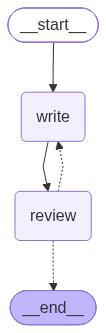

In [36]:
display(writer_graph)

### ▶️ 실행 도우미 — 멈출 때마다 사람에게 묻고 재개하기

`interrupt` 로 멈추면 `result["__interrupt__"]` 가 생깁니다. 이게 **있는 동안** 사람의 답으로 재개하는 것을 반복하면 됩니다.

> 🧑‍💻 아래 셀을 실행하면 입력창이 뜹니다. **`y`** 를 입력하면 승인, **그 외 문장**을 입력하면 피드백으로 전달됩니다.
> 예) `더 친근한 말투로`, `한 문장으로 줄여줘`, `제목을 붙여줘`

In [37]:
def run_writer(topic: str, thread_id: str) -> str:
    config = {"configurable": {"thread_id": thread_id}}
    result = writer_graph.invoke({"topic": topic, "revisions": 0, "draft": "", "feedback": ""}, config)

    while "__interrupt__" in result:                                  # 🛑 멈춰 있는 동안 반복
        info = result["__interrupt__"][0].value
        print(f"\n📝 [초안 {info['revisions']}차]\n{info['draft']}\n")
        answer = input("🙋 승인은 y, 수정 요청은 피드백을 입력 > ").strip()

        if answer.lower() in ("y", "yes"):
            resume = {"approved": True}
        else:
            resume = {"approved": False, "feedback": answer}
        result = writer_graph.invoke(Command(resume=resume), config)      # 사람의 답으로 재개

    return result["draft"]

final = run_writer("AI 시대에 개발자가 배워야 할 것", thread_id="writer-1")
print("\n🏆 최종 글:\n", final)

   ✍️ [write] 1번째 작성 완료

📝 [초안 1차]
AI 시대에 개발자는 데이터 분석과 머신러닝의 기초를 이해하는 것이 중요합니다. 또한, 협업과 커뮤니케이션 능력을 강화하여 다양한 분야의 전문가들과 효과적으로 소통할 수 있어야 합니다. 마지막으로, 지속적인 학습과 적응력을 통해 빠르게 변화하는 기술 환경에 대응하는 것이 필수적입니다.


🏆 최종 글:
 AI 시대에 개발자는 데이터 분석과 머신러닝의 기초를 이해하는 것이 중요합니다. 또한, 협업과 커뮤니케이션 능력을 강화하여 다양한 분야의 전문가들과 효과적으로 소통할 수 있어야 합니다. 마지막으로, 지속적인 학습과 적응력을 통해 빠르게 변화하는 기술 환경에 대응하는 것이 필수적입니다.


**📝 정리** — 1차 초안에 `y`로 바로 승인해서 피드백 루프는 돌지 않았다. 피드백을 입력하면 `review`가 `Command(goto="write", update={"feedback": ...})`로 되돌아가고, 3번째 작성 후에는 `MAX_REVISIONS`로 끝난다.

| 흐름 | 일어나는 일 |
|------|-------------|
| `write` 실행 | LLM 이 초안 작성 (`revisions=1`) |
| `review` 도달 | `interrupt` 로 **멈춤** → `result["__interrupt__"]` 에 초안이 담겨 옴 |
| 사람이 `y` | `Command(resume={"approved": True})` → `review` 가 `END` 로 이동 → **종료** |
| 사람이 피드백 입력 | `review` 가 `Command(goto="write", update={"feedback": ...})` → **write 로 되돌아감** |
| 다시 `write` | 피드백이 있으므로 **수정 프롬프트**로 LLM 호출 → 다시 `review` 에서 멈춤 (**루프**) |
| 3번 작성 후에도 승인 안 됨 | `MAX_REVISIONS` 안전장치로 **종료** |

### 🧠 이 예제가 보여 주는 LangGraph 의 가치
- **루프 + 사람 개입 + 상태 저장**이 코드 몇십 줄로 자연스럽게 표현됩니다.
- 같은 로직을 `while` 문과 `input()` 으로 짜면 **웹 서비스(요청-응답)** 로 옮길 때 구조를 통째로 갈아엎어야 합니다.
  LangGraph 는 `result["__interrupt__"]` 를 API 로 내려보내고, 사람의 응답이 오면 **같은 `thread_id` 로 `Command(resume=...)`** 만 호출하면 되므로 **웹 서비스에도 그대로** 쓸 수 있습니다.

## 🎓 21장. 정리 — 치트시트 · 연습문제 · 다음 단계

### 🗺️ 개념 지도

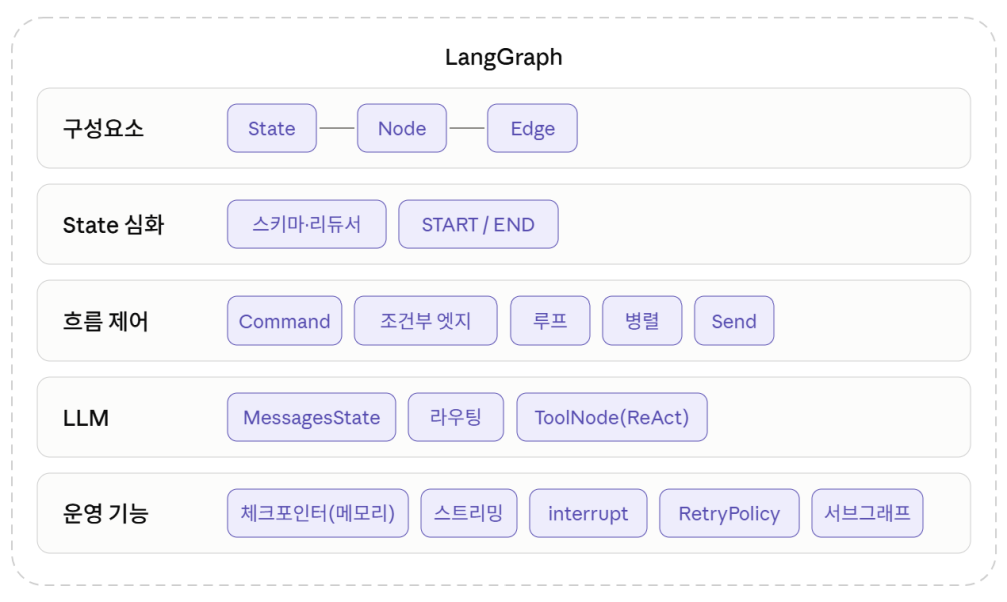

### 📋 치트시트

| 하고 싶은 일 | 코드 |
|--------------|------|
| 그래프 만들기 | `b = StateGraph(State)` → `b.add_node(...)` → `b.add_edge(...)` → `g = b.compile()` |
| 실행 | `g.invoke(입력)`, `g.stream(입력, stream_mode=...)`, `g.batch([...])` |
| 상태 필드 이어붙이기 | `x: Annotated[list, operator.add]` |
| 대화 메시지 State | `MessagesState` (`add_messages` 리듀서 내장) |
| 분기 | `b.add_conditional_edges("A", 라우팅함수)` (반환 `Literal[...]`) |
| 반복 | 조건부 엣지의 목적지를 **앞 노드**로 + `recursion_limit` |
| 병렬 fan-out / fan-in | `add_edge(START, "a")`, `add_edge(START, "b")` / `add_edge(["a","b"], "join")` |
| 동적 병렬 | 라우팅 함수에서 `[Send("노드", 입력), ...]` 반환 |
| 노드가 직접 이동 | `return Command(update={...}, goto="노드")` |
| 실행 설정 주입 | `StateGraph(S, context_schema=Ctx)` + `invoke(..., context=Ctx(...))` + `runtime: Runtime[Ctx]` |
| 도구 에이전트 | `llm.bind_tools` + `ToolNode(tools)` + `tools_condition` + `add_edge("tools","agent")` |
| 메모리 | `compile(checkpointer=InMemorySaver())` + `config={"configurable":{"thread_id":"..."}}` |
| 상태 조회 | `g.get_state(config)`, `g.get_state_history(config)` |
| 사람에게 묻기 | 노드에서 `answer = interrupt(값)` → 재개 `g.invoke(Command(resume=값), config)` |
| 재시도 | `add_node("n", fn, retry_policy=RetryPolicy(max_attempts=3))` |
| 서브그래프 | `parent.add_node("이름", 컴파일된_서브그래프)` |
| 시각화 | `g.get_graph(xray=True).draw_mermaid_png()` |

### 🧠 꼭 기억할 원칙 7가지

1. **노드는 "바뀐 것만" dict 로 반환**한다 (State 를 직접 수정하지 않는다)
2. **"어떻게 합칠지"는 State(리듀서)의 책임**이다 — 병렬·메시지 누적에 필수
3. **같은 슈퍼스텝의 노드는 서로의 결과를 못 본다** (병렬 실행)
4. **fan-in 은 리스트**로: `add_edge([a, b], "join")`
5. 루프에는 **반드시 종료 조건 + 상한**(`recursion_limit` 또는 카운터)을 둔다
6. `interrupt()` 재개 시 **노드가 처음부터 재실행**된다 → 앞쪽에 **부작용 금지**
7. **State = 흐르며 바뀌는 데이터, Context = 변하지 않는 실행 설정**

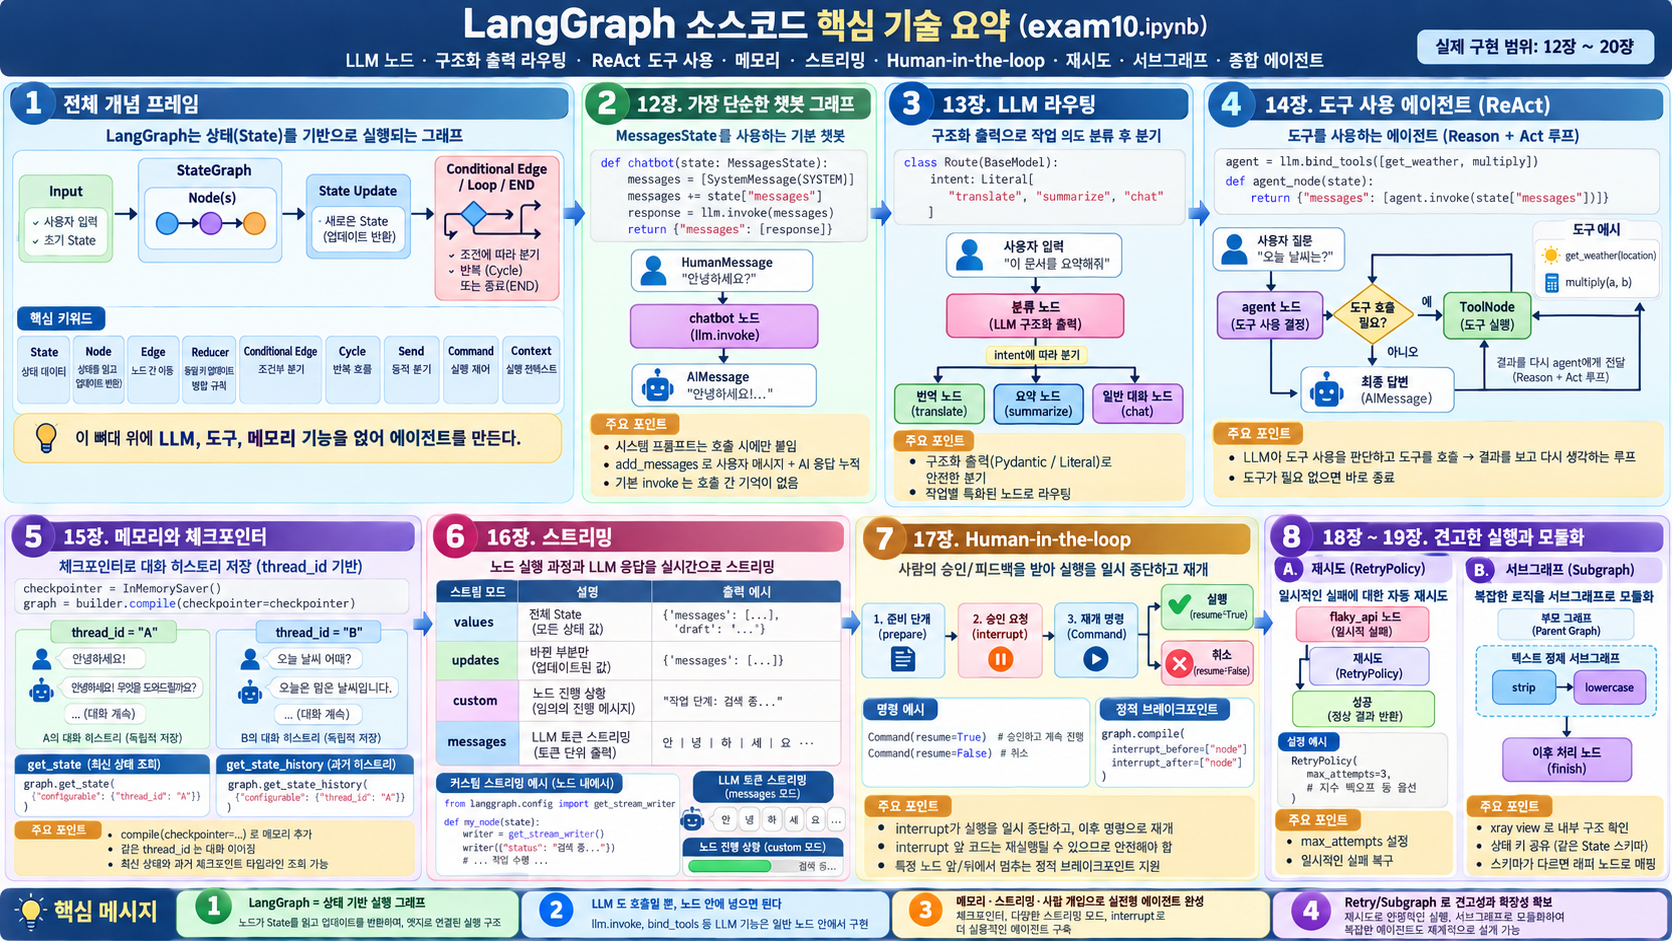

## 🔁 복습 질문

<details>
<summary>1. ReAct 그래프를 만드는 네 부품은?</summary>

`llm.bind_tools`, `ToolNode(tools)`, `tools_condition`, `add_edge("tools", "agent")` 사이클.
</details>

<details>
<summary>2. 체크포인터를 쓸 때 호출마다 꼭 넘겨야 하는 것은?</summary>

`config={"configurable": {"thread_id": ...}}`.
</details>

<details>
<summary>3. <code>interrupt()</code>로 멈춘 그래프를 재개하는 방법은?</summary>

같은 `thread_id`로 `invoke(Command(resume=사람의 답), config)`. 그 값이 `interrupt()`의 반환값이 된다.
</details>

<details>
<summary>4. <code>RetryPolicy</code>와 미들웨어 재시도의 차이는?</summary>

RetryPolicy는 그래프의 노드 하나에, 미들웨어 재시도는 create_agent의 모델·도구 호출에 붙는다.
</details>
